In [2]:
# # 07 - Experiments: comparison, cold-start, sensitivity, ablation
# All final hyperparameters come from `config.yaml` (`model:` section, filled after notebooks 03-06).
# Models are fitted on train + validation and evaluated on the test set, unless stated otherwise.

# %%
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from uniguide.config import get_path, load_config
from uniguide.data.stats import save_fig
from uniguide.evaluation.experiments import (
    across_seeds, ablation_models, cold_course_experiment, cold_user_experiment,
    evaluate_models, neighbors_experiment, select_best_alpha, sparsity_experiment, summarize)
from uniguide.pipeline import build_cf, build_hybrid, model_factories

cfg = load_config()
SEED = cfg["seed"]
K_VALUES = tuple(cfg["evaluation"]["k_values"])
SEEDS = [SEED + i for i in range(cfg["evaluation"]["n_seeds"])]
p = get_path("processed")
tables = get_path("results") / "tables"
tables.mkdir(parents=True, exist_ok=True)

train, val, test = (pd.read_parquet(p / f"{n}.parquet") for n in ["train", "val", "test"])
cold_course_test = pd.read_parquet(p / "cold_course_test.parquet")
courses = pd.read_parquet(p / "courses.parquet")                      # full catalogue (cold courses included)
cold_courses = sorted(json.loads((p / "cold_courses.json").read_text()))
courses_warm = courses[~courses["course_id"].isin(cold_courses)].reset_index(drop=True)
cold_users = json.loads((p / "cold_users.json").read_text())
train_val = pd.concat([train, val], ignore_index=True)
factories = model_factories()
print(f"train+val {len(train_val):,} | test {len(test):,} | cold courses {len(cold_courses)} "
      f"| cold users { {k: len(v) for k, v in cold_users.items()} }")


train+val 98,513 | test 24,629 | cold courses 42 | cold users {'0': 445, '1': 445, '3': 445, '5': 445}


In [3]:
# ## 1. Main comparison
# Same test users and same K for every method. Std and 95% CI are computed over users.

# %%
models = {name: factory().fit(train_val, courses_warm) for name, factory in factories.items()}
models["hybrid_rrf"] = build_hybrid(rrf=True).fit(train_val, courses_warm)

per_user = evaluate_models(models, test, K_VALUES, experiment="main", seed=SEED, per_user=True)
for name in models:
    per_user[per_user["method"] == name].to_csv(tables / f"eval_{name}.csv", index=False)

main = summarize(per_user)
main.to_csv(tables / "summary_main.csv", index=False)
print(f"{per_user.groupby('method').size().iloc[0] // (len(K_VALUES) * 4):,} evaluated users")
main[main["k"] == 10].pivot(index="method", columns="metric", values="mean").round(4)

# %%
# Mean +- 95% CI at K = 10
m10 = main[main["k"] == 10]
(m10.assign(txt=lambda d: d["mean"].round(4).astype(str) + " +- " + d["ci95"].round(4).astype(str))
     .pivot(index="method", columns="metric", values="txt"))


14,039 evaluated users


metric,hit_rate,ndcg,precision,recall
method,,,,
collaborative,0.1 +- 0.005,0.0379 +- 0.0022,0.0103 +- 0.0005,0.0734 +- 0.004
content_based,0.2042 +- 0.0067,0.0969 +- 0.0037,0.0216 +- 0.0007,0.1591 +- 0.0057
hybrid,0.1823 +- 0.0064,0.0865 +- 0.0036,0.0191 +- 0.0007,0.1444 +- 0.0055
hybrid_rrf,0.171 +- 0.0062,0.0711 +- 0.0031,0.0178 +- 0.0007,0.131 +- 0.0052
popularity,0.279 +- 0.0074,0.1092 +- 0.0034,0.033 +- 0.001,0.1966 +- 0.0059


history,0,1,3,5
method,,,,
collaborative,0.0923,0.0962,0.0674,0.0490
content_based,0.0966,0.0966,0.0863,0.0696
hybrid,0.0923,0.0967,0.0854,0.0648
popularity,0.1089,0.1073,0.1084,0.1167


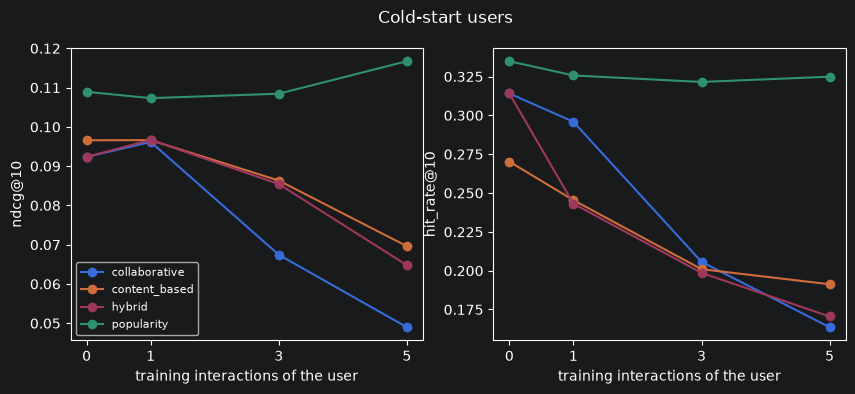

In [4]:
# ## 2. Cold-start users (0, 1, 3 and 5 training interactions)
# The training history of each cold group is truncated to its most recent interactions; every method is refitted once.

# %%
cold_u = cold_user_experiment(factories, train_val, test, courses_warm, cold_users, K_VALUES, seed=SEED)
cold_u["history"] = cold_u["experiment"].str.replace("cold_users_", "").astype(int)
cold_u.to_csv(tables / "exp_cold_users.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharex=True)
for ax, metric in zip(axes, ["ndcg", "hit_rate"]):
    sub = cold_u[(cold_u["k"] == 10) & (cold_u["metric"] == metric)]
    for method, g in sub.groupby("method"):
        g = g.sort_values("history")
        ax.plot(g["history"], g["value"], marker="o", label=method)
    ax.set(xlabel="training interactions of the user", ylabel=f"{metric}@10", xticks=sorted(cold_u["history"].unique()))
axes[0].legend(fontsize=8)
fig.suptitle("Cold-start users")
save_fig(fig, "cold_start_users")
cold_u[(cold_u["k"] == 10) & (cold_u["metric"] == "ndcg")].pivot(index="method", columns="history", values="value").round(4)


42 new courses, 9,514 users in the cold-course test


k                   5                                  10                    \
metric        hit_rate    ndcg precision  recall hit_rate    ndcg precision   
method                                                                        
collaborative   0.0000  0.0000    0.0000  0.0000   0.0000  0.0000    0.0000   
content_based   0.5304  0.3283    0.1202  0.4163   0.6457  0.3691    0.0787   
hybrid          0.5304  0.3283    0.1202  0.4163   0.6457  0.3691    0.0787   
popularity      0.0000  0.0000    0.0000  0.0000   0.0000  0.0000    0.0000   

k                      
metric         recall  
method                 
collaborative  0.0000  
content_based  0.5291  
hybrid         0.5291  
popularity     0.0000

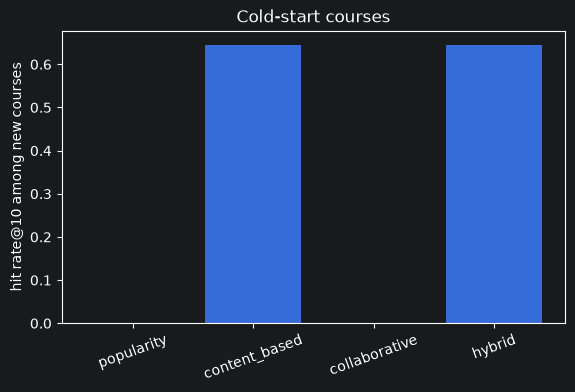

In [5]:
# ## 3. Cold-start courses
# New courses (absent from every training set) are ranked among themselves. CF has no score for them;
# popularity has no signal. Only text-based methods (content, hybrid) can do better than chance.
# The reference for chance is `1 / number of new courses` per recommended slot.

# %%
cold_c = cold_course_experiment(factories, train_val, cold_course_test, courses, cold_courses, K_VALUES, seed=SEED)
cold_c.to_csv(tables / "exp_cold_courses.csv", index=False)
print(f"{len(cold_courses)} new courses, {cold_course_test['user_id'].nunique():,} users in the cold-course test")

fig, ax = plt.subplots(figsize=(6.5, 3.8))
sub = cold_c[(cold_c["k"] == 10) & (cold_c["metric"] == "hit_rate")]
ax.bar(sub["method"], sub["value"])
ax.set(ylabel="hit rate@10 among new courses", title="Cold-start courses")
ax.tick_params(axis="x", rotation=20)
save_fig(fig, "cold_start_courses")
cold_c.pivot_table(index="method", columns=["k", "metric"], values="value").round(4)


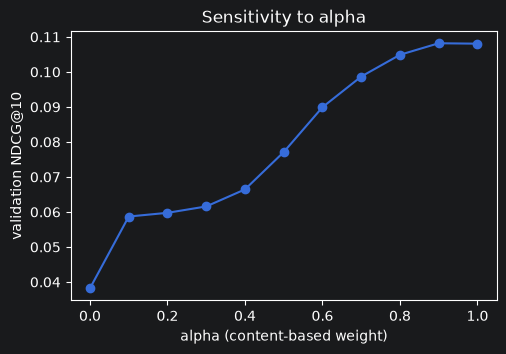

In [6]:
# ## 4. Sensitivity
# ### 4.1 alpha (validation)

# %%
rng = np.random.default_rng(SEED)
val_users = val["user_id"].unique()
sample = rng.choice(val_users, size=min(3000, len(val_users)), replace=False)
val_sample = val[val["user_id"].isin(sample)]

hybrid_ref = build_hybrid()
best_alpha, alpha_table = select_best_alpha(
    hybrid_ref.content_model, hybrid_ref.collaborative_model, train, courses_warm, val_sample, k=10)
alpha_table.to_csv(tables / "exp_sensitivity_alpha.csv", index=False)
fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.plot(alpha_table["alpha"], alpha_table["ndcg@10"], marker="o")
ax.set(xlabel="alpha (content-based weight)", ylabel="validation NDCG@10", title="Sensitivity to alpha")
save_fig(fig, "sensitivity_alpha")

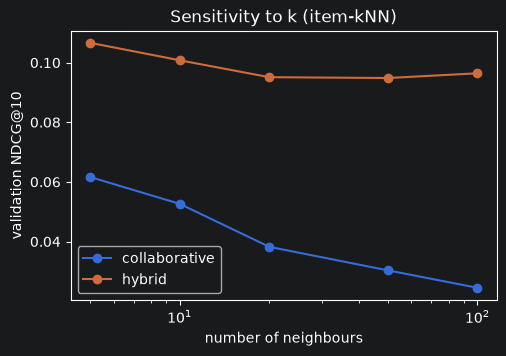

In [7]:
# ### 4.2 Number of neighbours (validation)

# %%
neigh = neighbors_experiment(build_cf, build_hybrid, train, val_sample, courses_warm)
neigh["n_neighbors"] = neigh["experiment"].str.replace("neighbors_", "").astype(int)
neigh.to_csv(tables / "exp_sensitivity_neighbors.csv", index=False)

fig, ax = plt.subplots(figsize=(5.5, 3.5))
for method, g in neigh[neigh["metric"] == "ndcg"].groupby("method"):
    g = g.sort_values("n_neighbors")
    ax.plot(g["n_neighbors"], g["value"], marker="o", label=method)
ax.set(xlabel="number of neighbours", ylabel="validation NDCG@10", xscale="log", title="Sensitivity to k (item-kNN)")
ax.legend()
save_fig(fig, "sensitivity_neighbors")

removed_%,0,25,50
method,,,
collaborative,0.0379,0.0464,0.0561
content_based,0.0969,0.0957,0.0951
hybrid,0.0865,0.0876,0.0916
popularity,0.1092,0.1076,0.1061


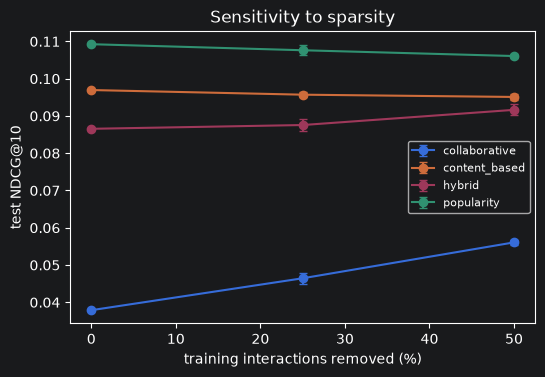

In [8]:
# ### 4.3 Sparsity (25% and 50% of the training interactions removed)
# Each user keeps its latest interaction. Removal is random: mean +- std over seeds.

# %%
sparse = sparsity_experiment(factories, train_val, test, courses_warm, fractions=(0.0, 0.25, 0.5),
                             seeds=SEEDS, k_values=(10,))
sparse.to_csv(tables / "exp_sparsity_runs.csv", index=False)
sp = across_seeds(sparse)
sp["removed_%"] = sp["experiment"].str.replace("sparsity_", "").astype(int)
sp.to_csv(tables / "exp_sparsity.csv", index=False)

fig, ax = plt.subplots(figsize=(6, 3.8))
for method, g in sp[sp["metric"] == "ndcg"].groupby("method"):
    g = g.sort_values("removed_%")
    ax.errorbar(g["removed_%"], g["mean"], yerr=g["std"].fillna(0), marker="o", capsize=3, label=method)
ax.set(xlabel="training interactions removed (%)", ylabel="test NDCG@10", title="Sensitivity to sparsity")
ax.legend(fontsize=8)
save_fig(fig, "sensitivity_sparsity")
sp[sp["metric"] == "ndcg"].pivot(index="method", columns="removed_%", values="mean").round(4)


In [9]:
# ## 5. Ablation: hybrid without CB / without CF / without switching
# `no_cb` = CF only (content kept only for courses CF cannot score); `no_cf` = content only.

# %%
ablation = ablation_models(models["hybrid"])
abl = summarize(evaluate_models(ablation, test, K_VALUES, experiment="ablation", seed=SEED, per_user=True))
abl.to_csv(tables / "exp_ablation.csv", index=False)
abl[abl["k"] == 10].pivot(index="method", columns="metric", values="mean").round(4)

# %%
# The ablation matters most for short histories: refit each variant on the cold-start groups.
abl_factories = {
    "hybrid_full": lambda: build_hybrid(),
    "hybrid_no_switching": lambda: build_hybrid(alpha_schedule=[]),
    "hybrid_no_cb": lambda: build_hybrid(alpha=0.0, alpha_schedule=[]),
    "hybrid_no_cf": lambda: build_hybrid(alpha=1.0, alpha_schedule=[]),
}
abl_cold = cold_user_experiment(abl_factories, train_val, test, courses_warm, cold_users, (10,), seed=SEED)
abl_cold["history"] = abl_cold["experiment"].str.replace("cold_users_", "").astype(int)
abl_cold.to_csv(tables / "exp_ablation_cold_users.csv", index=False)
abl_cold[abl_cold["metric"] == "ndcg"].pivot(index="method", columns="history", values="value").round(4)


history,0,1,3,5
method,,,,
hybrid_full,0.0923,0.0967,0.0854,0.0648
hybrid_no_cb,0.0923,0.0962,0.0674,0.0490
hybrid_no_cf,0.0923,0.0966,0.0863,0.0696
hybrid_no_switching,0.0923,0.0931,0.0747,0.0566
